# Модель прогнозирования риска засухи
Обучение CatBoostClassifier на основе метеорологических показателей и индекса вегетации NDVI.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from catboost import CatBoostClassifier
from sklearn.metrics import classification_report, roc_auc_score
from sklearn.model_selection import train_test_split


## 1. Загрузка данных и разметка признаков

In [2]:
# Загрузка объединенного датасета
df = pd.read_csv("final_drought_dataset.csv")
df["date"] = pd.to_datetime(df["date"])
df = df.sort_values("date").reset_index(drop=True)

# Формирование целевой метки: падение NDVI более чем на 15% относительно 30-дневного среднего
df["ndvi_rolling_mean"] = df["ndvi"].rolling(window=30, min_periods=5).mean()
df["drought_target"] = (df["ndvi"] < (df["ndvi_rolling_mean"] * 0.85)).astype(int)

df = df.dropna().reset_index(drop=True)

feature_cols = ["temp_max", "temp_mean", "precip_sum", "soil_moisture_mean", "ndvi"]
X = df[feature_cols]
y = df["drought_target"]

print(f"Размер выборки: {len(df)} строк")
print("Баланс классов:")
print(y.value_counts())


Размер выборки: 284 строк
Баланс классов:
drought_target
0    230
1     54


## 2. Обучение CatBoostClassifier

In [3]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=False)

model = CatBoostClassifier(
    iterations=5000,
    learning_rate=0.003,
    depth=6,
    eval_metric="AUC",
    random_seed=42,
    verbose=500,
)

model.fit(
    X_train,
    y_train,
    eval_set=(X_test, y_test),
)


0:	test: 0.4818182	best: 0.4818182 (0)
500:	test: 0.5000000	best: 0.7363636 (44)
1000:	test: 0.3636364	best: 0.7363636 (44)
1500:	test: 0.3818182	best: 0.7363636 (44)
2000:	test: 0.4545455	best: 0.7363636 (44)
2500:	test: 0.4818182	best: 0.7363636 (44)
3000:	test: 0.5000000	best: 0.7363636 (44)
3500:	test: 0.5090909	best: 0.7363636 (44)
4000:	test: 0.4818182	best: 0.7363636 (44)
4500:	test: 0.5272727	best: 0.7363636 (44)
4999:	test: 0.5727273	best: 0.7363636 (44)

bestTest = 0.7363636364
bestIteration = 44

Shrink model to first 45 iterations.


## 3. Метрики качества

In [4]:
preds = model.predict(X_test)
probs = model.predict_proba(X_test)[:, 1]

print("--- Отчет классификации ---")
print(classification_report(y_test, preds, zero_division=0))

try:
    print(f"ROC-AUC: {roc_auc_score(y_test, probs):.4f}")
except Exception as e:
    print(f"Не удалось рассчитать ROC-AUC: {e}")

model.save_model("drought_catboost_model.cbm")
print("\nМодель сохранена в drought_catboost_model.cbm")


--- Отчет классификации ---
              precision    recall  f1-score   support

           0       0.96      1.00      0.98        55
           1       0.00      0.00      0.00         2

    accuracy                           0.96        57
   macro avg       0.48      0.50      0.49        57
weighted avg       0.93      0.96      0.95        57

ROC-AUC: 0.7364

Модель сохранена в drought_catboost_model.cbm


## 4. Важность признаков

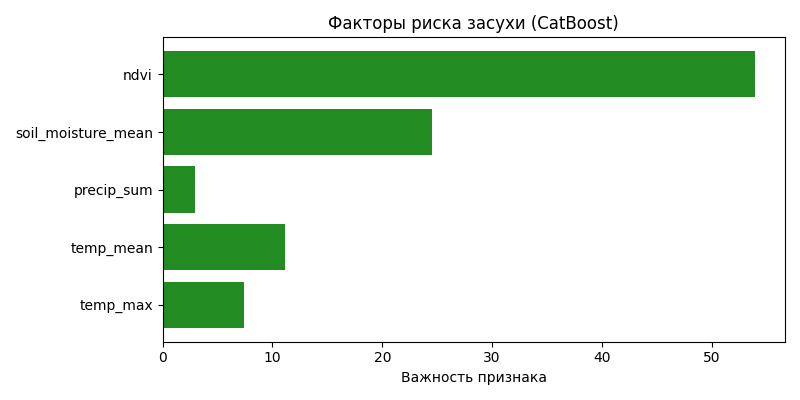

In [5]:
importances = model.get_feature_importance()

plt.figure(figsize=(8, 4))
plt.barh(feature_cols, importances, color="forestgreen")
plt.xlabel("Важность признака")
plt.title("Факторы риска засухи (CatBoost)")
plt.tight_layout()
plt.show()
